In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.cluster import KMeans
np.random.seed(42)
NOTA_MINIMA, FALTA_MAXIMA = 60.0, 25.0   # regra da Entrega 1

df = pd.read_excel("Historico.xlsx", sheet_name="Sheet1")
d = df[df["Situação"].isin(["Aprovado", "Reprovado"])].dropna(subset=["% Nota Obtida", "% de Faltas"])
d = d[(d["% Nota Obtida"] <= 100) & (d["% de Faltas"] <= 100) & (d["Aulas Ministradas"] > 0)].copy()
d["reprovado"] = (d["Situação"] == "Reprovado").astype(int)
print("Registros originais:", len(df), "| após limpeza:", len(d))

def agrega(g):
    w = g["Aulas Ministradas"].to_numpy(float)
    return pd.Series({"nota_pond": np.dot(g["% Nota Obtida"], w) / w.sum(),
                      "faltas_pond": np.dot(g["% de Faltas"], w) / w.sum(),
                      "n_disc": len(g), "carga_total": w.sum(), "reprovou": int(g["reprovado"].max())})

S = d.groupby(["ID_ALUNO", "Ano/Semestre Letivo"]).apply(agrega, include_groups=False).reset_index()
S = S.sample(n=6000, random_state=42).reset_index(drop=True)
feat = ["nota_pond", "faltas_pond", "n_disc", "carga_total"]
X = S[feat].to_numpy(float); y = S["reprovou"].to_numpy()
print("Matriz X:", X.shape, "| alunos-semestre com reprovação: %.1f%%" % (100 * y.mean()))
print(S[feat].describe().round(2))

Registros originais: 274901 | após limpeza: 211562
Matriz X: (6000, 4) | alunos-semestre com reprovação: 24.4%
       nota_pond  faltas_pond   n_disc  carga_total
count    6000.00      6000.00  6000.00      6000.00
mean       74.84         6.33     5.46       413.74
std        17.19         6.46     1.53       115.22
min         0.00         0.00     1.00        28.00
25%        68.84         0.95     5.00       374.00
50%        77.57         4.63     5.00       412.00
75%        86.06         9.96     6.00       432.00
max       100.00        61.90    14.00      1208.00


Variância explicada SEM padronizar: [0.976 0.021 0.003 0.   ]
Variância explicada COM padronização: [0.481 0.313 0.163 0.044]

               PC1    PC2    PC3    PC4
nota_pond    0.322  0.603 -0.730 -0.006
faltas_pond -0.182 -0.717 -0.672  0.038
n_disc       0.662 -0.224  0.101  0.708
carga_total  0.652 -0.269  0.071 -0.705

PC1 sem padronizar: {'nota_pond': np.float64(0.026), 'faltas_pond': np.float64(-0.001), 'n_disc': np.float64(0.011), 'carga_total': np.float64(1.0)}
Nº de condição (covariância bruta): 17648 | (correlação): 10.89


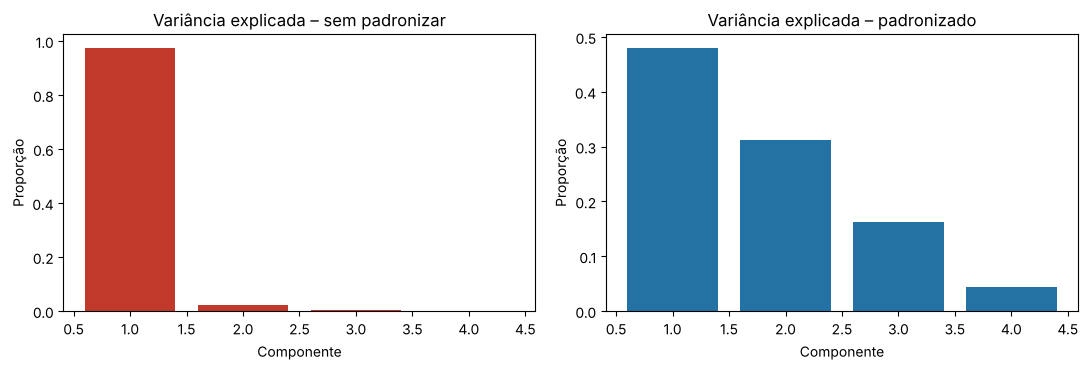

In [2]:
def pca(M):
    Mc = M - M.mean(axis=0)
    U, s, Vt = np.linalg.svd(Mc, full_matrices=False)
    var = s**2 / (len(M) - 1)
    return Mc, Vt, var / var.sum()

_, Vt_raw, ev_raw = pca(X)
Z = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)
Zc, Vt, ev = pca(Z)

print("Variância explicada SEM padronizar:", np.round(ev_raw, 3))
print("Variância explicada COM padronização:", np.round(ev, 3))
print()
print(pd.DataFrame(Vt.T, index=feat, columns=["PC1", "PC2", "PC3", "PC4"]).round(3))
print()
print("PC1 sem padronizar:", dict(zip(feat, np.round(Vt_raw[0], 3))))
print("Nº de condição (covariância bruta): %.0f | (correlação): %.2f" % (np.linalg.cond(np.cov(X.T)), np.linalg.cond(np.cov(Z.T))))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(range(1, 5), ev_raw, color="#c0392b"); ax[0].set_title("Variância explicada – sem padronizar")
ax[1].bar(range(1, 5), ev, color="#2471a3"); ax[1].set_title("Variância explicada – padronizado")
for a in ax: a.set_xlabel("Componente"); a.set_ylabel("Proporção")
plt.tight_layout(); plt.show()

## 3. Projeção em 2D e projeção sobre o eixo de risco

Eixo de risco: {'nota_pond': np.float64(-0.921), 'faltas_pond': np.float64(0.35), 'n_disc': np.float64(-0.139), 'carga_total': np.float64(-0.1)}
Projeção média sem reprovação: -0.43 | com reprovação: 1.32
Cosseno eixo de risco x PC1: 0.517 (ângulo 58.9°)


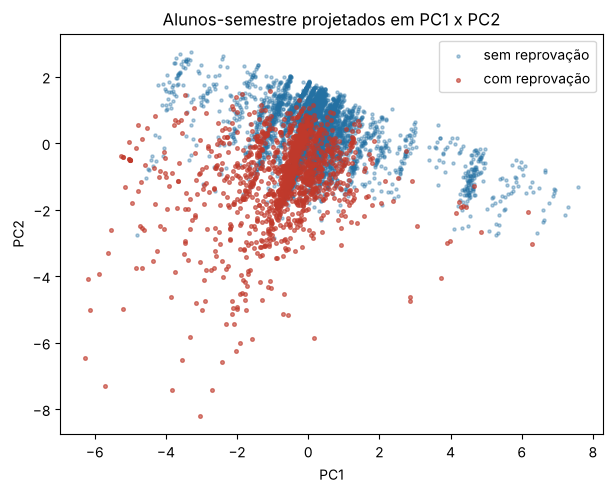

In [3]:
P = Zc @ Vt[:2].T   # transformação linear R^4 -> R^2
fig, ax = plt.subplots(figsize=(7, 5.2))
ax.scatter(P[y == 0, 0], P[y == 0, 1], s=5, alpha=0.35, c="#2471a3", label="sem reprovação")
ax.scatter(P[y == 1, 0], P[y == 1, 1], s=7, alpha=0.6, c="#c0392b", label="com reprovação")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(); ax.set_title("Alunos-semestre projetados em PC1 x PC2")
plt.show()

# eixo de risco: do centróide "sem reprovação" ao centróide "com reprovação"
r = Z[y == 1].mean(axis=0) - Z[y == 0].mean(axis=0)
r_hat = r / np.linalg.norm(r)
proj = Z @ r_hat    # projeção escalar sobre vetor unitário
print("Eixo de risco:", dict(zip(feat, np.round(r_hat, 3))))
print("Projeção média sem reprovação: %.2f | com reprovação: %.2f" % (proj[y == 0].mean(), proj[y == 1].mean()))
c = abs(r_hat @ Vt[0]); print("Cosseno eixo de risco x PC1: %.3f (ângulo %.1f°)" % (c, np.degrees(np.arccos(c))))

## 4. Sensibilidade dos limiares e dos pesos da regra

Regra da Entrega 1 (nota<60 ou faltas>25): F1 = 0.670
Melhor da grade: nota<67.5 ou faltas>32.5 -> F1 = 0.798
F1 varia de 0.439 a 0.798 na grade

Peso w em score = w*margem_nota + (1-w)*margem_falta (alerta se score < 0):
  w=0.00 sinalizados=  1.2% precisão=0.915 recall=0.044
  w=0.25 sinalizados=  2.6% precisão=0.987 recall=0.106
  w=0.50 sinalizados=  5.9% precisão=0.997 recall=0.239
  w=0.75 sinalizados=  9.1% precisão=0.998 recall=0.371
  w=0.90 sinalizados= 11.2% precisão=0.994 recall=0.454
  w=1.00 sinalizados= 12.5% precisão=0.989 recall=0.505


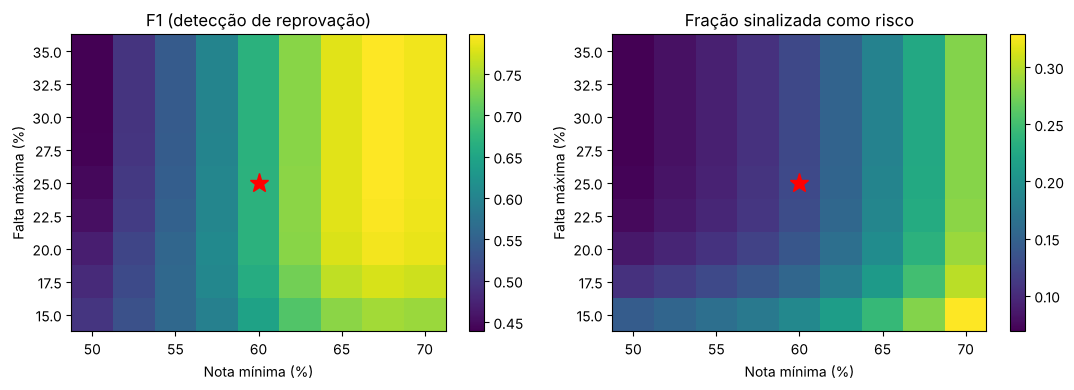

In [4]:
notas = np.arange(50, 71, 2.5); faltas = np.arange(15, 36, 2.5)
F1 = np.zeros((len(faltas), len(notas))); SINAL = np.zeros_like(F1)
for i, fm in enumerate(faltas):
    for j, nm in enumerate(notas):
        pred = ((S["nota_pond"] < nm) | (S["faltas_pond"] > fm)).to_numpy().astype(int)
        tp = ((pred == 1) & (y == 1)).sum(); fp = ((pred == 1) & (y == 0)).sum(); fn = ((pred == 0) & (y == 1)).sum()
        prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
        F1[i, j] = 2 * prec * rec / max(prec + rec, 1e-9); SINAL[i, j] = pred.mean()

bi = np.unravel_index(F1.argmax(), F1.shape)
print("Regra da Entrega 1 (nota<60 ou faltas>25): F1 = %.3f" % F1[list(faltas).index(25.0), list(notas).index(60.0)])
print("Melhor da grade: nota<%.1f ou faltas>%.1f -> F1 = %.3f" % (notas[bi[1]], faltas[bi[0]], F1[bi]))
print("F1 varia de %.3f a %.3f na grade" % (F1.min(), F1.max()))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, M_, t in zip(ax, [F1, SINAL], ["F1 (detecção de reprovação)", "Fração sinalizada como risco"]):
    im = a.imshow(M_, origin="lower", aspect="auto", cmap="viridis",
                  extent=[notas[0]-1.25, notas[-1]+1.25, faltas[0]-1.25, faltas[-1]+1.25])
    a.set_xlabel("Nota mínima (%)"); a.set_ylabel("Falta máxima (%)"); a.set_title(t); plt.colorbar(im, ax=a)
    a.plot(60, 25, "r*", ms=14)
plt.tight_layout(); plt.show()

mn = (S["nota_pond"] - NOTA_MINIMA) / 100; mf = (FALTA_MAXIMA - S["faltas_pond"]) / 100
print("\nPeso w em score = w*margem_nota + (1-w)*margem_falta (alerta se score < 0):")
for w in [0.0, 0.25, 0.5, 0.75, 0.9, 1.0]:
    flag = ((w * mn + (1 - w) * mf) < 0).to_numpy().astype(int)
    tp = ((flag == 1) & (y == 1)).sum(); fp = ((flag == 1) & (y == 0)).sum(); fn = ((flag == 0) & (y == 1)).sum()
    print("  w=%.2f sinalizados=%5.1f%% precisão=%.3f recall=%.3f" % (w, 100*flag.mean(), tp/max(tp+fp,1), tp/max(tp+fn,1)))

## 5. Agrupamentos (k-means) no espaço padronizado

         nota_pond  faltas_pond  n_disc  carga_total  reprovou  tamanho
cluster                                                                
0            80.55         2.39    5.26       394.51      0.13     3355
1            73.58        12.17    5.60       428.51      0.31     1897
2            35.91        12.17    3.69       285.37      0.84      479
3            81.73         3.84   10.19       777.99      0.08      269


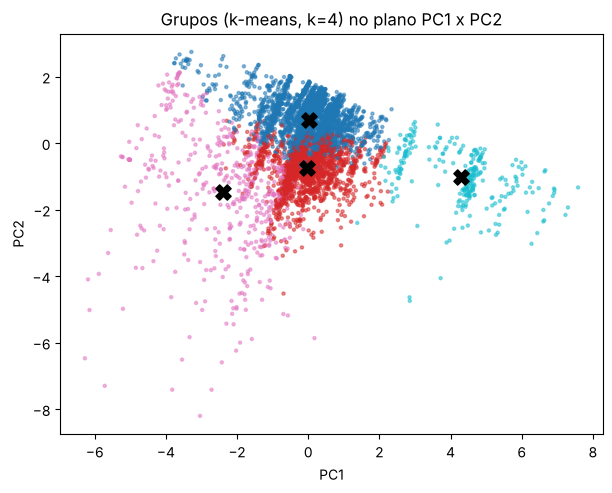

In [5]:
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(Z)
lab = km.labels_
res = S.assign(cluster=lab).groupby("cluster")[feat + ["reprovou"]].mean().round(2)
res["tamanho"] = np.bincount(lab)
print(res)

fig, ax = plt.subplots(figsize=(7, 5.2))
ax.scatter(P[:, 0], P[:, 1], c=lab, s=5, cmap="tab10", alpha=0.5)
cent = km.cluster_centers_ @ Vt[:2].T
ax.scatter(cent[:, 0], cent[:, 1], c="k", marker="X", s=120)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("Grupos (k-means, k=4) no plano PC1 x PC2")
plt.show()

## 6. Estabilidade da solução

In [6]:
cos1, cos2 = [], []
for _ in range(200):
    idx = np.random.randint(0, len(Z), len(Z))
    Zb = Z[idx]; Zb = Zb - Zb.mean(0)
    _, _, Vtb = np.linalg.svd(Zb, full_matrices=False)
    cos1.append(abs(Vtb[0] @ Vt[0])); cos2.append(abs(Vtb[1] @ Vt[1]))
print("Bootstrap (200 reamostragens) – |cos| com a direção original")
print("PC1: média %.4f, mínimo %.4f" % (np.mean(cos1), np.min(cos1)))
print("PC2: média %.4f, mínimo %.4f" % (np.mean(cos2), np.min(cos2)))

Bootstrap (200 reamostragens) – |cos| com a direção original
PC1: média 0.9990, mínimo 0.9942
PC2: média 0.9989, mínimo 0.9939
